# Lab 1 plots


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from utilities import FileReader

%config InlineBackend.figure_format = 'retina'

DATA_DIR = Path('.')               # folder with the *_content_<motion>.csv files and map.pgm/map.yaml
FIG_DIR = Path('report/figures')   # PNGs for the LaTeX report go here
FIG_DIR.mkdir(parents=True, exist_ok=True)
MOTIONS = ['line', 'circle', 'spiral']

UNWRAP_THETA = True                               # show full turns as a ramp instead of jumps at +/-pi

In [2]:
# First three slots of a colour-blind-checked categorical palette, always used in this order
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK_2, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
FULL_WIDTH = 6.3   # [in] \textwidth of the report (letter paper, 2.8 cm side margins)

plt.rcParams.update({
    'font.size': 8, 'axes.titlesize': 9, 'figure.titlesize': 10, 'legend.fontsize': 8,
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': '#c3c2b7',
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'lines.linewidth': 1.0, 'lines.markersize': 4,
    'legend.frameon': False, 'savefig.bbox': 'tight', 'savefig.dpi': 300,
})

## Load the logs

`FileReader` from `utilities.py` returns one row per message, with the stamp in nanoseconds in the last column. Each motion gets one time zero (its earliest stamp across the three sensors), so IMU, odom and scan times line up.

In [3]:
def load(sensor, motion):
    # One CSV -> float array, one row per logged message
    _, rows = FileReader(DATA_DIR / f'{sensor}_content_{motion}.csv').read_file()
    return np.array(rows)

data = {m: {s: load(s, m) for s in ('imu', 'odom', 'laser')} for m in MOTIONS}
t0 = {m: min(d[0, -1] for d in data[m].values()) for m in MOTIONS}

def seconds(motion, sensor):
    # Message times in seconds from the start of that motion's run
    return (data[motion][sensor][:, -1] - t0[motion]) * 1e-9

## Data check

Message counts, rates and the largest gap between messages show whether anything dropped out. The inf share counts laser beams with no return.

In [4]:
print(f"{'motion':8}{'sensor':7}{'msgs':>6}{'duration':>10}{'rate':>9}{'max gap':>9}")
for m in MOTIONS:
    for s in ('imu', 'odom', 'laser'):
        t = seconds(m, s)
        span = t[-1] - t[0]
        print(f"{m:8}{s:7}{len(t):6d}{span:9.1f}s{(len(t) - 1) / span:7.1f}Hz{np.diff(t).max():8.2f}s")
    ranges = data[m]['laser'][:, :-3]
    print(f"{'':15}{np.mean(~np.isfinite(ranges)):.0%} of laser beams are inf/NaN\n")

motion  sensor   msgs  duration     rate  max gap
line    imu       407     12.2s   33.3Hz    0.04s
line    odom      244     12.1s   20.0Hz    0.07s
line    laser      75     10.0s    7.4Hz    0.15s
               33% of laser beams are inf/NaN

circle  imu       522     15.8s   33.0Hz    0.09s
circle  odom      306     15.2s   20.0Hz    0.07s
circle  laser     112     15.6s    7.1Hz    0.42s
               33% of laser beams are inf/NaN

spiral  imu      3019     90.8s   33.2Hz    0.06s
spiral  odom     1817     90.8s   20.0Hz    0.07s
spiral  laser     645     88.7s    7.3Hz    0.27s
               33% of laser beams are inf/NaN



## Odometry: x vs y

Path in the odom frame. The odom frame starts where the robot booted, not where each run began, so the start points are not at the origin.

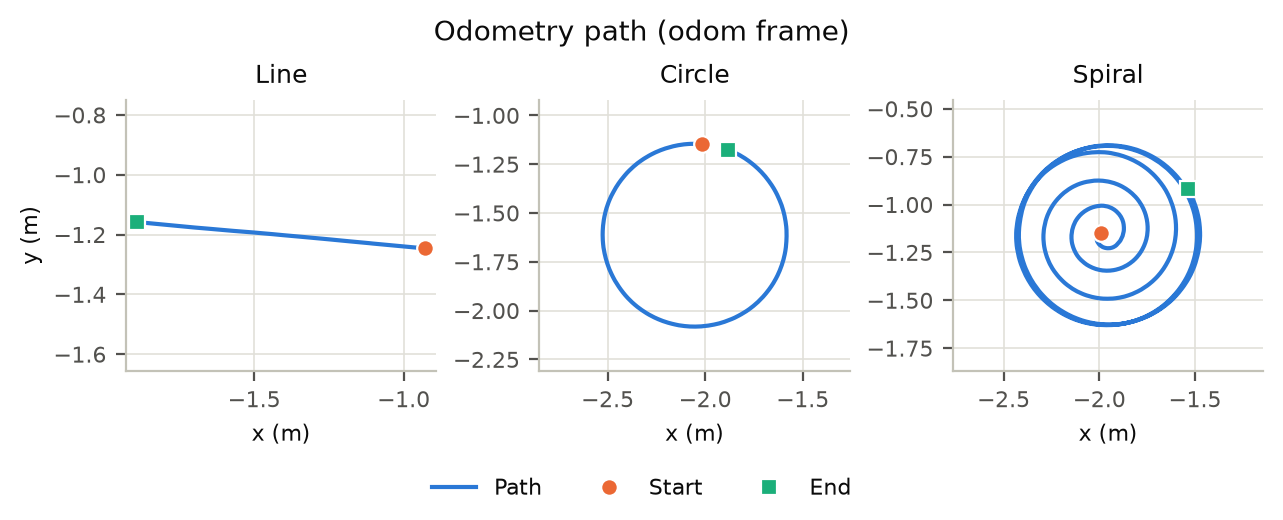

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH, 2.5), layout='constrained')
for ax, m in zip(axes, MOTIONS):
    x, y = data[m]['odom'][:, 0], data[m]['odom'][:, 1]
    ax.plot(x, y, color=BLUE, lw=1.5, label='Path')
    ax.plot(x[0], y[0], 'o', ms=6, color=ORANGE, mec='white', mew=0.8, label='Start')
    ax.plot(x[-1], y[-1], 's', ms=6, color=AQUA, mec='white', mew=0.8, label='End')
    ax.set(title=m.capitalize(), xlabel='x (m)')
    ax.set_aspect('equal', adjustable='datalim')
axes[0].set_ylabel('y (m)')
fig.suptitle('Odometry path (odom frame)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=3)
fig.savefig(FIG_DIR / 'odom_xy.png')
plt.show()

## Odometry: x, y, θ vs t

θ is the yaw that `euler_from_quaternion` produced while logging. With `UNWRAP_THETA` it is unwrapped, so a constant turn rate shows up as a straight ramp whose slope is the angular velocity.

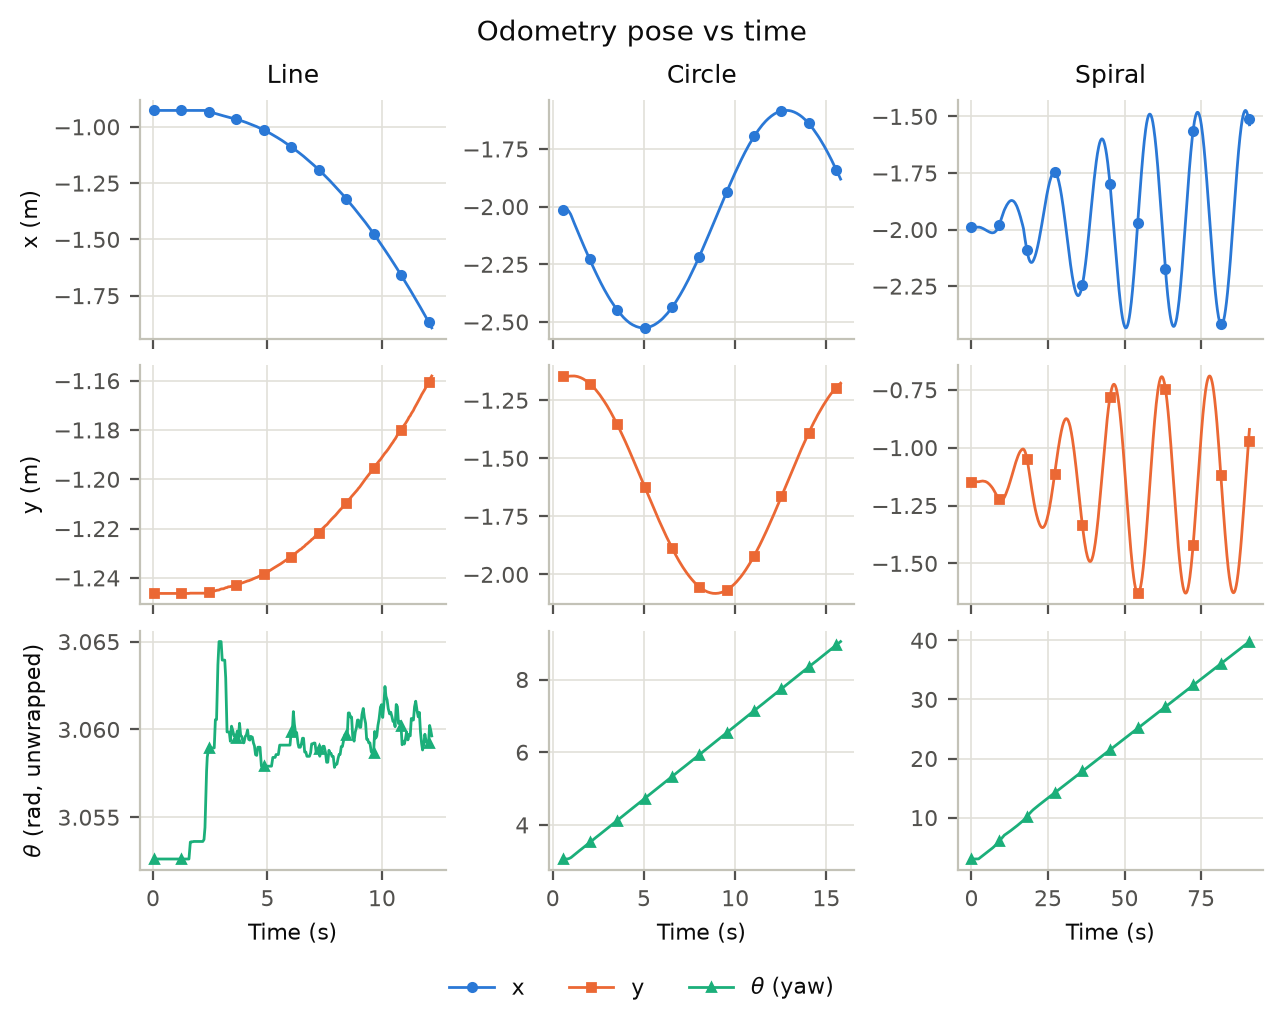

In [6]:
odom_rows = [('x', 'x (m)', BLUE, 'o'),
             ('y', 'y (m)', ORANGE, 's'),
             (r'$\theta$ (yaw)', r'$\theta$ (rad, unwrapped)' if UNWRAP_THETA else r'$\theta$ (rad)', AQUA, '^')]
fig, axes = plt.subplots(3, 3, figsize=(FULL_WIDTH, 5), sharex='col', layout='constrained')
for col, m in enumerate(MOTIONS):
    t = seconds(m, 'odom')
    x, y, th = data[m]['odom'][:, :3].T
    if UNWRAP_THETA:
        th = np.unwrap(th)
    for row, (values, (label, _, color, marker)) in enumerate(zip((x, y, th), odom_rows)):
        axes[row, col].plot(t, values, color=color, marker=marker, ms=3, markevery=max(len(t) // 10, 1), label=label)
    axes[0, col].set_title(m.capitalize())
    axes[-1, col].set_xlabel('Time (s)')
for row, (_, ylabel, _, _) in enumerate(odom_rows):
    axes[row, 0].set_ylabel(ylabel)
handles = [axes[row, 0].get_legend_handles_labels()[0][0] for row in range(3)]
fig.suptitle('Odometry pose vs time')
fig.legend(handles=handles, loc='outside lower center', ncol=3)
fig.savefig(FIG_DIR / 'odom_vs_time.png')
plt.show()

## SLAM map

`map.pgm` with the resolution and origin from `map.yaml`, so the axes are in metres in the map frame. Black is occupied, white is free, gray is unknown. The plot is cropped to the explored area.

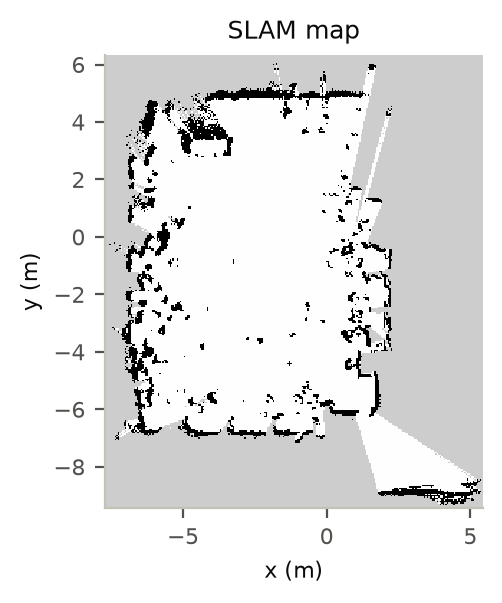

In [7]:
meta = dict(line.split(':', 1) for line in (DATA_DIR / 'map.yaml').read_text().splitlines() if ':' in line)
res = float(meta['resolution'])
ox, oy = (float(v) for v in meta['origin'].strip(' []').split(',')[:2])
img = np.array(Image.open(DATA_DIR / meta['image'].strip()))

# Crop to the explored cells plus a small border
rows, cols = np.nonzero(img != 205)
pad = 5
r0, r1 = max(rows.min() - pad, 0), min(rows.max() + pad + 1, img.shape[0])
c0, c1 = max(cols.min() - pad, 0), min(cols.max() + pad + 1, img.shape[1])
h = img.shape[0]   # image row 0 is the top of the map (largest y)
extent = [ox + c0 * res, ox + c1 * res, oy + (h - r1) * res, oy + (h - r0) * res]

fig, ax = plt.subplots(figsize=(FULL_WIDTH / 2, 2.9), layout='constrained')
ax.imshow(img[r0:r1, c0:c1], cmap='gray', vmin=0, vmax=255, extent=extent, interpolation='nearest')
ax.set(title='SLAM map', xlabel='x (m)', ylabel='y (m)')
ax.grid(False)
fig.savefig(FIG_DIR / 'map.png')
plt.show()